In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [5]:
#To List set the data on for Data Analyst in United States
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

#Droping the Nan values in salary_year_avg numerical data
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])

<Axes: >

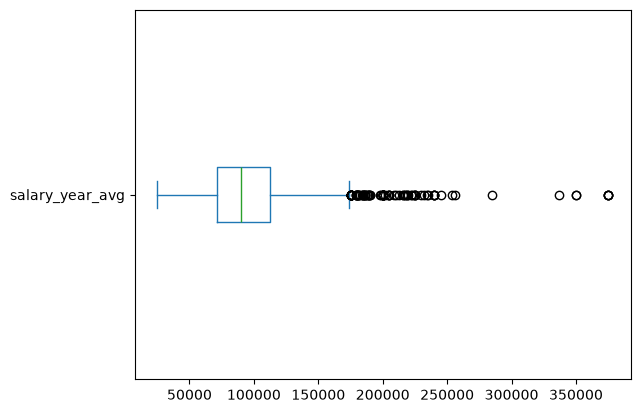

In [8]:
df_DA_US['salary_year_avg'].plot(kind='box', vert=False)

C:\Users\hp\AppData\Local\Temp\ipykernel_25048\1981918594.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list, tick_labels=job_titles, vert=False)


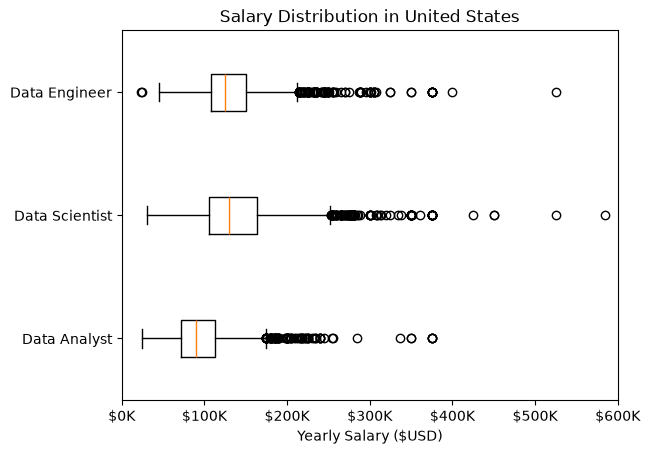

In [31]:
job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer']

#filtering the data to only focus on the title in job_title
df_US = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'United States')]

#Droping the Nan values in salary_year_avg numeric data
df_US = df_US.dropna(subset=['salary_year_avg'])

job_list = [df_US[df_US['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]

plt.boxplot(job_list, tick_labels=job_titles, vert=False)
plt.title('Salary Distribution in United States')
plt.xlabel('Yearly Salary ($USD)')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'${int(x/1000)}K'))
plt.xlim(0, 600000)
plt.show()